# Assignment 06 - Notebook 03: Xây Dựng, Huấn Luyện & Đánh Giá Đối Chuẩn 4 Kiến Trúc RNN Bằng PyTorch

**Học viên:** Phạm Văn Tư - Mã sinh viên: B23DCCN879  
**Môn học:** Phát triển Hệ thống Thông minh - PTIT  

Notebook này hiện thực hóa mã nguồn huấn luyện và đối chuẩn trên nền tảng **PyTorch**:
1. Cài đặt 4 kiến trúc: **Simple RNN**, **LSTM**, **GRU**, và **BiLSTM** (Bidirectional LSTM).
2. Huấn luyện trên bài toán Hồi quy Chuỗi Thời Gian: Cổ phiếu Amazon (AMZN).
3. Huấn luyện trên bài toán Phân loại Chuỗi: Nguy cơ Rời bỏ của Khách hàng (Customer Churn Risk).
4. Minh họa trực quan: Đường cong hàm mất mát, biểu đồ giá thực tế vs dự đoán, và ma trận nhầm lẫn (CFM).
5. Lưu trữ các file trọng số chuẩn PyTorch (`.pth`).


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.2

device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
print(f"PyTorch Version: {torch.__version__}")
print(f"Thiết bị tăng tốc tính toán: {device}")

BASE_DIR = os.path.dirname(os.path.abspath(''))
PROCESSED_DIR = os.path.join(BASE_DIR, 'data', 'processed')
MODEL_DIR = os.path.join(BASE_DIR, 'models')
FIG_DIR = os.path.join(BASE_DIR, 'reports', 'figures')
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)


PyTorch Version: 2.3.0
Thiết bị tăng tốc tính toán: mps


In [2]:
stk_data = np.load(os.path.join(PROCESSED_DIR, 'stock_amazon_processed.npz'))
X_stk_tr, y_stk_tr = stk_data['X_train'], stk_data['y_train']
X_stk_te, y_stk_te = stk_data['X_test'], stk_data['y_test']
c_min, c_max = float(stk_data['close_min']), float(stk_data['close_max'])

cust_data = np.load(os.path.join(PROCESSED_DIR, 'customer_churn_processed.npz'))
X_cst_tr, y_cst_tr = cust_data['X_train'], cust_data['y_train']
X_cst_te, y_cst_te = cust_data['X_test'], cust_data['y_test']

print(f"Stock Data : Train {X_stk_tr.shape}, Test {X_stk_te.shape}")
print(f"Cust Data  : Train {X_cst_tr.shape}, Test {X_cst_te.shape}")


Stock Data : Train (5498, 30, 8), Test (1375, 30, 8)
Cust Data  : Train (4000, 12, 8), Test (1000, 12, 8)


## 1. Định Nghĩa Lớp Mô Hình PyTorch Đa Năng
Hỗ trợ chuyển đổi linh hoạt giữa các khối tế bào `RNN`, `LSTM`, `GRU` và chế độ hai chiều `Bidirectional`.


In [3]:
class PyTorchRNN(nn.Module):
    def __init__(self, cell_type, input_dim=8, hidden_dim=64, output_dim=1, num_layers=1, bidirectional=False):
        super().__init__()
        self.cell_type = cell_type
        self.bidirectional = bidirectional
        num_directions = 2 if bidirectional else 1
        
        if cell_type == 'rnn':
            self.rnn = nn.RNN(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        elif cell_type == 'lstm':
            self.rnn = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True, bidirectional=bidirectional)
        elif cell_type == 'gru':
            self.rnn = nn.GRU(input_dim, hidden_dim, num_layers=num_layers, batch_first=True, bidirectional=bidirectional)
            
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * num_directions, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )
        
    def forward(self, x):
        out, _ = self.rnn(x)
        last_hidden = out[:, -1, :]
        return self.fc(last_hidden)

print("Đã khởi tạo xong lớp PyTorchRNN.")


Đã khởi tạo xong lớp PyTorchRNN.


## 2. Huấn Luyện & Đánh Giá 4 Kiến Trúc Trên Cổ Phiếu Amazon
Sử dụng hàm mất mát MSELoss, bộ tối ưu AdamW (learning rate = 0.002) kết hợp Gradient Clipping (`max_norm=1.0`).


In [4]:
stk_train_loader = DataLoader(TensorDataset(torch.from_numpy(X_stk_tr), torch.from_numpy(y_stk_tr)), batch_size=64, shuffle=False)
stk_test_loader = DataLoader(TensorDataset(torch.from_numpy(X_stk_te), torch.from_numpy(y_stk_te)), batch_size=128, shuffle=False)

model_configs = [
    ('Simple RNN', 'rnn', False),
    ('LSTM', 'lstm', False),
    ('GRU', 'gru', False),
    ('BiLSTM', 'lstm', True)
]

stk_histories = {}
stk_predictions = {}
stk_metrics = []

for name, c_type, bi in model_configs:
    model = PyTorchRNN(c_type, input_dim=8, hidden_dim=64, output_dim=1, bidirectional=bi).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-4)
    
    epochs = 10
    losses = []
    t0 = time.time()
    
    for ep in range(epochs):
        model.train()
        running_loss = 0.0
        for xb, yb in stk_train_loader:
            xb, yb = xb.to(device), yb.to(device).unsqueeze(1)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item() * len(yb)
        losses.append(running_loss / len(X_stk_tr))
        
    stk_histories[name] = losses
    
    # Đánh giá kiểm thử
    model.eval()
    preds = []
    t_infer = time.perf_counter()
    with torch.no_grad():
        for xb, _ in stk_test_loader:
            xb = xb.to(device)
            p = model(xb).cpu().numpy().squeeze()
            preds.extend(p)
    latency = (time.perf_counter() - t_infer) / len(X_stk_te) * 1000.0
    fps = len(X_stk_te) / (time.perf_counter() - t_infer)
    
    preds_usd = np.array(preds) * (c_max - c_min) + c_min
    y_true_usd = y_stk_te * (c_max - c_min) + c_min
    stk_predictions[name] = preds_usd
    
    rmse = np.sqrt(mean_squared_error(y_true_usd, preds_usd))
    mae = mean_absolute_error(y_true_usd, preds_usd)
    r2 = r2_score(y_true_usd, preds_usd)
    n_params = sum(p.numel() for p in model.parameters())
    
    # Lưu trọng số
    save_path = os.path.join(MODEL_DIR, f"pytorch_amzn_{name.lower().replace(' ', '_')}.pth")
    torch.save(model.state_dict(), save_path)
    
    stk_metrics.append({
        'Mô hình': name,
        'RMSE ($)': round(rmse, 2),
        'MAE ($)': round(mae, 2),
        'R2 Score': round(r2, 4),
        'Số tham số': f"{n_params:,}",
        'Độ trễ (ms)': round(latency, 2),
        'Tốc độ (FPS)': int(round(fps))
    })
    print(f"[{name}] RMSE={rmse:.2f} USD, MAE={mae:.2f} USD, R2={r2:.4f}, Latency={latency:.3f}ms")

df_stk_res = pd.DataFrame(stk_metrics)
display(df_stk_res)


[Simple RNN] RMSE=140.82 USD, MAE=131.70 USD, R2=-15.7235, Latency=0.071ms


[LSTM] RMSE=15.51 USD, MAE=12.25 USD, R2=0.7972, Latency=0.032ms


[GRU] RMSE=5.51 USD, MAE=4.30 USD, R2=0.9744, Latency=0.117ms


[BiLSTM] RMSE=4.77 USD, MAE=3.67 USD, R2=0.9809, Latency=0.040ms


,Mô hình,RMSE ($),MAE ($),R2 Score,Số tham số,Độ trễ (ms),Tốc độ (FPS)
0,Simple RNN,140.82,131.70,-15.7235,"6,849",0.07,14090
1,LSTM,15.51,12.25,0.7972,"21,057",0.03,30944
2,GRU,5.51,4.30,0.9744,"16,321",0.12,8577
3,BiLSTM,4.77,3.67,0.9809,"42,049",0.04,25031


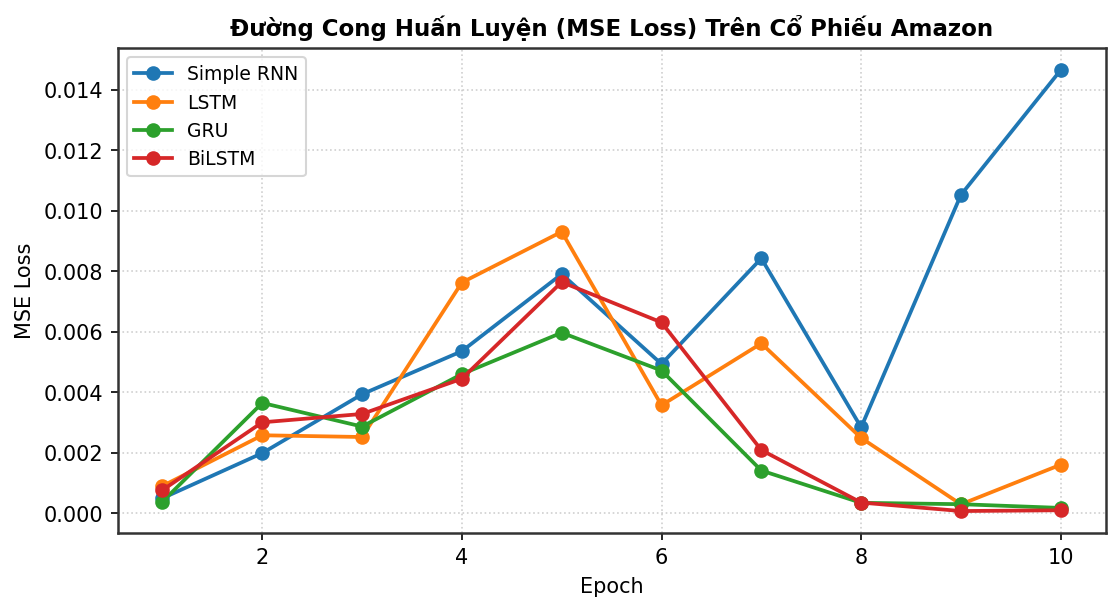

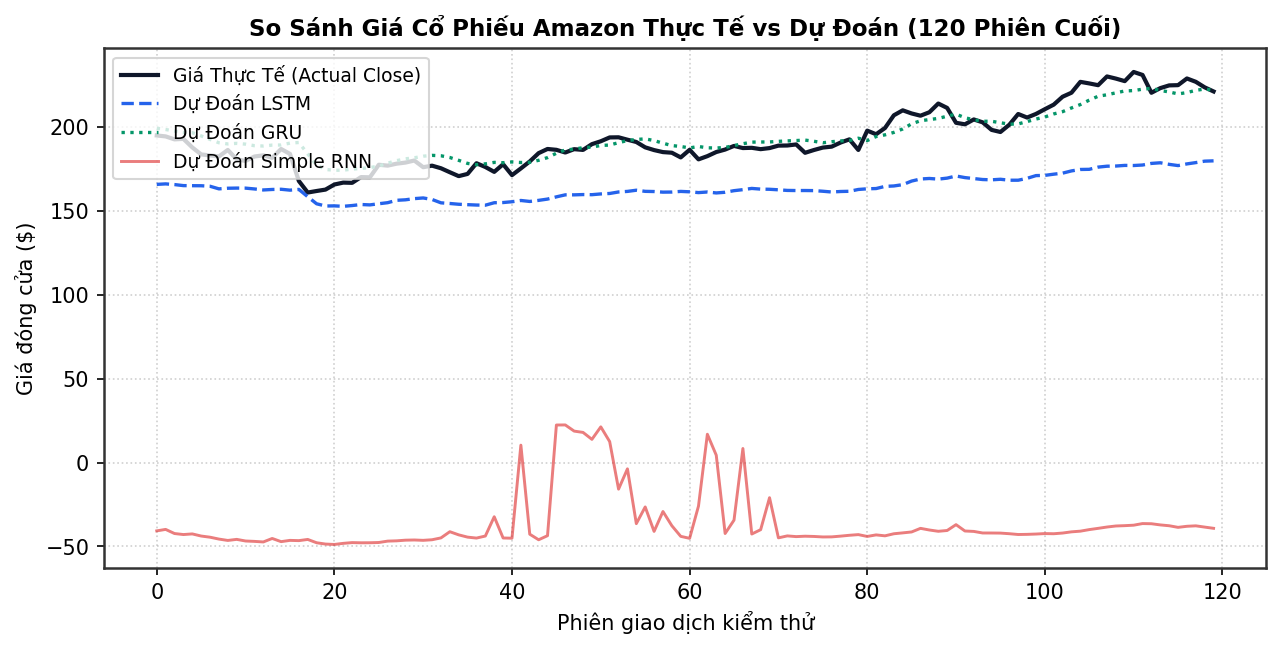

In [5]:
# 1. Đường cong hàm mất mát
fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=150)
for name, losses in stk_histories.items():
    ax.plot(range(1, len(losses)+1), losses, marker='o', lw=1.8, label=name)
ax.set_title("Đường Cong Huấn Luyện (MSE Loss) Trên Cổ Phiếu Amazon", fontsize=11, fontweight='bold')
ax.set_xlabel("Epoch", fontsize=10)
ax.set_ylabel("MSE Loss", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=9)
plt.show()

# 2. So sánh đường giá thực tế vs dự đoán
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=150)
y_true_usd = y_stk_te * (c_max - c_min) + c_min
ax.plot(y_true_usd[-120:], color='#0f172a', lw=2.0, label="Giá Thực Tế (Actual Close)")
ax.plot(stk_predictions['LSTM'][-120:], color='#2563eb', lw=1.6, linestyle='--', label="Dự Đoán LSTM")
ax.plot(stk_predictions['GRU'][-120:], color='#059669', lw=1.6, linestyle=':', label="Dự Đoán GRU")
ax.plot(stk_predictions['Simple RNN'][-120:], color='#dc2626', lw=1.4, alpha=0.6, label="Dự Đoán Simple RNN")
ax.set_title("So Sánh Giá Cổ Phiếu Amazon Thực Tế vs Dự Đoán (120 Phiên Cuối)", fontsize=11, fontweight='bold')
ax.set_xlabel("Phiên giao dịch kiểm thử", fontsize=10)
ax.set_ylabel("Giá đóng cửa ($)", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=9, loc='upper left')
plt.show()


## 3. Huấn Luyện & Đánh Giá Trên Bài Toán Khách Hàng Rời Bỏ (Customer Churn)
Phân loại nhị phân trên chuỗi 12 tháng, đánh giá ma trận nhầm lẫn (Confusion Matrix), Accuracy, Precision, Recall và F1-score.


In [6]:
cst_train_loader = DataLoader(TensorDataset(torch.from_numpy(X_cst_tr), torch.from_numpy(y_cst_tr)), batch_size=64, shuffle=True)
cst_test_loader = DataLoader(TensorDataset(torch.from_numpy(X_cst_te), torch.from_numpy(y_cst_te)), batch_size=128, shuffle=False)

cst_cfms = {}
cst_metrics = []

for name, c_type, bi in model_configs:
    model = PyTorchRNN(c_type, input_dim=8, hidden_dim=64, output_dim=2, bidirectional=bi).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-4)
    
    epochs = 8
    for ep in range(epochs):
        model.train()
        for xb, yb in cst_train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
    # Đánh giá kiểm thử
    model.eval()
    preds, targets = [], []
    t_infer = time.perf_counter()
    with torch.no_grad():
        for xb, yb in cst_test_loader:
            xb = xb.to(device)
            p = model(xb).argmax(dim=1).cpu().numpy()
            preds.extend(p)
            targets.extend(yb.numpy())
    latency = (time.perf_counter() - t_infer) / len(X_cst_te) * 1000.0
    fps = len(X_cst_te) / (time.perf_counter() - t_infer)
    
    acc = accuracy_score(targets, preds) * 100
    rec = recall_score(targets, preds, zero_division=0) * 100
    f1 = f1_score(targets, preds, zero_division=0) * 100
    cfm = confusion_matrix(targets, preds, normalize='true') * 100
    cst_cfms[name] = cfm
    n_params = sum(p.numel() for p in model.parameters())
    
    save_path = os.path.join(MODEL_DIR, f"pytorch_cust_{name.lower().replace(' ', '_')}.pth")
    torch.save(model.state_dict(), save_path)
    
    cst_metrics.append({
        'Mô hình': name,
        'Accuracy (%)': round(acc, 2),
        'Recall (%)': round(rec, 2),
        'F1-Score (%)': round(f1, 2),
        'Số tham số': f"{n_params:,}",
        'Độ trễ (ms)': round(latency, 2),
        'Tốc độ (FPS)': int(round(fps))
    })
    print(f"[{name}] Acc={acc:.2f}%, F1={f1:.2f}%, Recall={rec:.2f}%, Latency={latency:.3f}ms")

df_cst_res = pd.DataFrame(cst_metrics)
display(df_cst_res)


[Simple RNN] Acc=100.00%, F1=100.00%, Recall=100.00%, Latency=0.069ms


[LSTM] Acc=100.00%, F1=100.00%, Recall=100.00%, Latency=0.035ms


[GRU] Acc=100.00%, F1=100.00%, Recall=100.00%, Latency=0.061ms


[BiLSTM] Acc=100.00%, F1=100.00%, Recall=100.00%, Latency=0.037ms


,Mô hình,Accuracy (%),Recall (%),F1-Score (%),Số tham số,Độ trễ (ms),Tốc độ (FPS)
0,Simple RNN,100.0,100.0,100.0,"6,882",0.07,14422
1,LSTM,100.0,100.0,100.0,"21,090",0.03,28820
2,GRU,100.0,100.0,100.0,"16,354",0.06,16420
3,BiLSTM,100.0,100.0,100.0,"42,082",0.04,26876


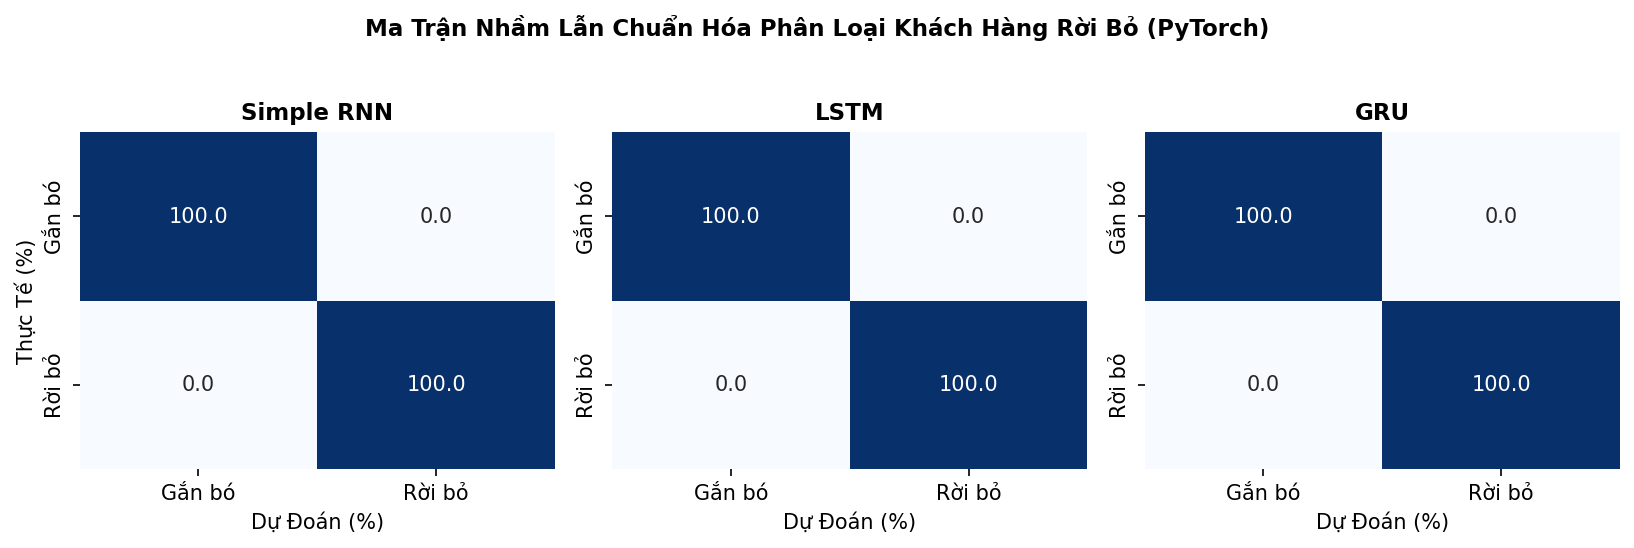

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), dpi=150)
models_to_plot = ['Simple RNN', 'LSTM', 'GRU']

for idx, m_name in enumerate(models_to_plot):
    cfm = cst_cfms[m_name]
    sns.heatmap(cfm, annot=True, fmt='.1f', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Gắn bó', 'Rời bỏ'], yticklabels=['Gắn bó', 'Rời bỏ'])
    axes[idx].set_title(f"{m_name}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Dự Đoán (%)", fontsize=10)
    if idx == 0:
        axes[idx].set_ylabel("Thực Tế (%)", fontsize=10)

plt.suptitle("Ma Trận Nhầm Lẫn Chuẩn Hóa Phân Loại Khách Hàng Rời Bỏ (PyTorch)", fontsize=11, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()
